# PyVBMC Example 9: Torch and JAX models and posterior exports

In this notebook, we fit a model whose likelihood is written in [Torch](https://pytorch.org/) (PyTorch), then bring the posterior back to Torch, to predict the model's responses, and to [ArviZ](https://www.arviz.org/), to summarize it. A final section writes the same likelihood in [JAX](https://docs.jax.dev/) and fits it again.

PyVBMC calls the target with NumPy arrays and expects NumPy values back, so a model written in any framework needs only a thin wrapper that converts between the two. A model that can evaluate many parameter vectors in one call can also take several points at once from PyVBMC. The model here is cheap, so that the notebook runs in seconds; PyVBMC is most useful when each evaluation of the likelihood is expensive.

This notebook is Part 9 of a series of notebooks in which we present various example usages for VBMC with the PyVBMC package. The code used in this example is available as a script [here](https://github.com/acerbilab/pyvbmc/blob/main/examples/scripts/pyvbmc_example_9_full_code.py). It needs Python 3.12 or newer and PyVBMC's optional `torch` and `arviz` dependencies, installed with `pip install --upgrade "pyvbmc[torch,arviz]"` (the [installation guide](https://acerbilab.org/pyvbmc/installation.html) explains how to install Torch for the CPU only). The last section also needs JAX, installed with `pip install jax`.

In [1]:
import sys

if "google.colab" in sys.modules:  # Colab lacks PyVBMC: install it
    %pip install --upgrade "pyvbmc[torch,arviz]"

In [2]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.special import expit

from pyvbmc import VBMC
from pyvbmc.priors import UniformBox

SEED = 9  # Fix the seed, so that the results below are reproducible

## 1. A psychometric model

At each stimulus level $s_i$, we observe $k_i$ correct responses in $n_i$ independent trials of a two-alternative task. We model

$$
k_i \sim \operatorname{Binomial}\bigl(n_i, p(s_i)\bigr), \qquad
p(s) = \gamma + (1-\gamma-\lambda) \operatorname{sigmoid}\bigl(\beta(s-\alpha)\bigr).
$$

The psychometric function $p(s)$ rises from $\gamma$, the probability of a correct guess, to $1 - \lambda$, where the lapse rate $\lambda$ is the probability of an error on an easy trial. We fix $\gamma = 0.5$ and $\lambda = 0.02$, and infer the two parameters that remain: the threshold $\alpha$, where the curve is halfway up, and the slope $\beta > 0$, which sets how steeply it rises.

We simulate 60 trials at each of 11 stimulus levels:

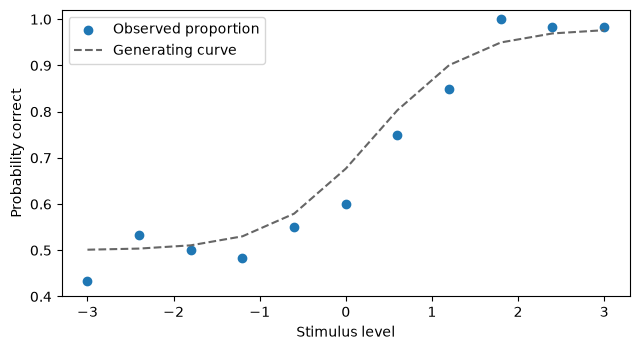

In [3]:
guess_rate = 0.5
lapse_rate = 0.02
stimulus = np.linspace(-3.0, 3.0, 11)
n_trials = np.full(stimulus.size, 60)
threshold_true, slope_true = 0.3, 1.8
probability_true = guess_rate + (1 - guess_rate - lapse_rate) * expit(
    slope_true * (stimulus - threshold_true)
)
rng = np.random.default_rng(SEED)
n_correct = rng.binomial(n_trials, probability_true)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.scatter(stimulus, n_correct / n_trials, label="Observed proportion")
ax.plot(
    stimulus, probability_true, "--", color="0.4", label="Generating curve"
)
ax.set(xlabel="Stimulus level", ylabel="Probability correct", ylim=(0.4, 1.02))
ax.legend()
fig.tight_layout()
plt.show()

## 2. A likelihood in Torch

The function `torch_log_likelihood` below is the target. It receives an array of parameter vectors, one per row, in the order `[threshold, slope]`, converts it to a Torch tensor, computes the binomial log-likelihood of the data for each row, and returns the values as a NumPy array. Two details matter:

- PyVBMC works in double precision, so the tensors are `float64`, which is not Torch's default.
- PyVBMC needs only the values of the likelihood, so the computation runs under `torch.no_grad()`, without recording gradients.

`Binomial.log_prob` includes the binomial coefficients. They are constant in the parameters, so they do not change the posterior, but they are part of the model evidence.

In [4]:
stimulus_t = torch.as_tensor(stimulus, dtype=torch.float64)
n_trials_t = torch.as_tensor(n_trials, dtype=torch.float64)
n_correct_t = torch.as_tensor(n_correct, dtype=torch.float64)


def response_probability_t(theta, levels):
    """Probability correct at each level, for each row [threshold, slope]."""
    threshold = theta[:, 0:1]
    slope = theta[:, 1:2]
    return guess_rate + (1 - guess_rate - lapse_rate) * torch.sigmoid(
        slope * (levels[None, :] - threshold)
    )


def torch_log_likelihood(x):
    """Binomial log-likelihood of the data, for each row of x."""
    with torch.no_grad():
        theta = torch.as_tensor(x, dtype=torch.float64)
        probabilities = response_probability_t(theta, stimulus_t)
        values = (
            torch.distributions.Binomial(
                total_count=n_trials_t, probs=probabilities
            )
            .log_prob(n_correct_t)
            .sum(dim=1)
        )
    return values.numpy()


# Two parameter vectors in, two log-likelihoods out:
check_points = np.array([[0.0, 1.0], [0.3, 1.8]])
torch_log_likelihood(check_points)

array([-36.16985449, -26.17829108])

On a GPU, create the tensors there (with `device=`) and return `values.cpu().numpy()`.

With the option `vectorized_target`, PyVBMC passes several points in one call where it can: the points of its initial design come in one batch, and each later point comes alone, as an array with one row.

## 3. Fit the threshold and the slope

As in the previous examples, we set the hard bounds, a plausible box where we expect most of the posterior mass, and a starting point. We put independent uniform priors on the threshold, in $[-3, 3]$, and on the slope, in $[0.2, 6]$, and pass them separately with `prior=`, as in Example 5: PyVBMC adds the log-prior to the log-likelihood that the target returns.

In [5]:
lower_bounds = np.array([[-3.0, 0.2]])
upper_bounds = np.array([[3.0, 6.0]])
plausible_lower = np.array([[-1.0, 0.5]])
plausible_upper = np.array([[1.0, 3.0]])
x0 = np.array([[0.0, 1.0]])
prior = UniformBox(lower_bounds, upper_bounds)

vbmc = VBMC(
    torch_log_likelihood,
    x0,
    lower_bounds,
    upper_bounds,
    plausible_lower,
    plausible_upper,
    prior=prior,
    options={"vectorized_target": True},
    seed=SEED,
)
vp, results = vbmc.optimize()

Beginning variational optimization assuming EXACT observations of the log-joint.
Performance settings: saved calibration.
Tip: Use PLB and PUB to guide PyVBMC's initial search toward likely parameter values. If you have no better information, use each prior's 16th and 84th percentiles: roughly mean minus and plus one SD for a Gaussian prior. These guide the search without affecting or restricting the posterior.
https://acerbilab.org/pyvbmc/faq.html#faq-how-do-i-choose-plb-and-pub
 Iteration  f-count    Mean[ELBO]    Std[ELBO]    sKL-iter[q]   K[q]  Convergence  Action
     0         10         -28.06         1.09    135863.91        2        inf     start warm-up
     1         15         -28.09         0.06         0.84        2        inf     
     2         20         -28.07         0.00         0.05        2       1.21     
     3         25         -28.07         0.00         0.00        2     0.0596     
     4         30         -28.07         0.00         0.00        2     0.07

## 4. Back to Torch

`vp.to_torch()` exports the variational posterior as a Torch distribution over `[threshold, slope]`, in the original parameter space. We draw parameter vectors from it and compute, for each, the probability of a correct response along the stimulus axis: the spread of these curves shows how uncertain the psychometric function remains after seeing the data.

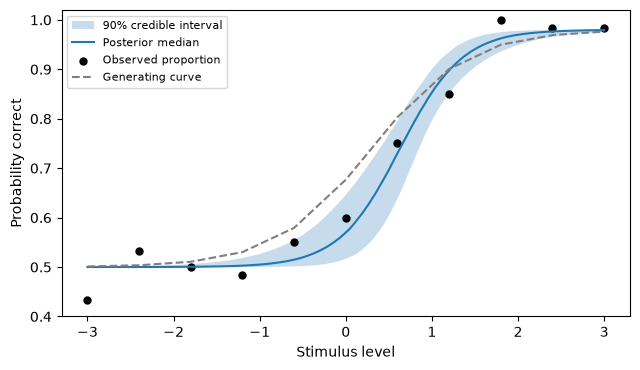

In [6]:
posterior_t = vp.to_torch()
torch.manual_seed(SEED)  # Sampling uses Torch's random generator
parameter_draws_t = posterior_t.sample((2000,))

levels_t = torch.linspace(-3.0, 3.0, 200, dtype=torch.float64)
probability_draws_t = response_probability_t(parameter_draws_t, levels_t)
bands = torch.quantile(
    probability_draws_t,
    torch.tensor([0.05, 0.5, 0.95], dtype=torch.float64),
    dim=0,
).numpy()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.fill_between(
    levels_t.numpy(),
    bands[0],
    bands[2],
    alpha=0.25,
    label="90% credible interval",
)
ax.plot(levels_t.numpy(), bands[1], label="Posterior median")
ax.scatter(
    stimulus,
    n_correct / n_trials,
    color="black",
    s=25,
    label="Observed proportion",
)
ax.plot(
    stimulus, probability_true, "--", color="0.5", label="Generating curve"
)
ax.set(xlabel="Stimulus level", ylabel="Probability correct", ylim=(0.4, 1.02))
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The band shows, at each stimulus level, the 90% credible interval of the probability of a correct response. The observed proportions scatter more widely, since each also varies with the binomial sampling of its 60 trials. The generating curve lies partly outside the band: by chance, these data favor a higher threshold.

The exported distribution is also differentiable. Its log density can enter other Torch computations, for example as the prior of a later analysis fit by gradient methods, and Torch computes its gradient with respect to the parameters:

In [7]:
point_t = parameter_draws_t[0].clone().requires_grad_(True)
log_density_t = posterior_t.log_prob(point_t)
gradient_t = torch.autograd.grad(log_density_t, point_t)[0]
print("Point [threshold, slope]:", point_t.detach().numpy())
print("Gradient of the log density:", gradient_t.numpy())

Point [threshold, slope]: [0.5033463  2.36891447]
Gradient of the log density: [3.3859662 0.1970632]


## 5. Summaries in ArviZ

`vp.to_arviz()` returns samples from the variational posterior as an ArviZ `DataTree`, under the names we give to the parameters:

In [8]:
posterior_data = vp.to_arviz(n_samples=2000, var_names=["threshold", "slope"])
az.summary(
    posterior_data,
    kind="stats",  # MCMC diagnostics do not apply to independent draws
    round_to=3,
)

,mean,sd,eti89_lb,eti89_ub
threshold,0.626,0.141,0.395,0.850
slope,2.926,0.737,1.952,4.267


## 6. The same likelihood in JAX

In JAX, the likelihood takes the same form. JAX computes in single precision unless told otherwise, so we enable [64-bit computation](https://docs.jax.dev/en/latest/default_dtypes.html) before creating any array. `jax.jit` compiles the computation on its first call for each shape of the input, and the wrapper returns the result as a NumPy array:

In [9]:
import jax

jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
from jax.scipy.stats import binom

stimulus_j = jnp.asarray(stimulus, dtype=jnp.float64)
n_trials_j = jnp.asarray(n_trials, dtype=jnp.float64)
n_correct_j = jnp.asarray(n_correct, dtype=jnp.float64)


@jax.jit
def jax_log_likelihood_values(theta):
    threshold = theta[:, 0:1]
    slope = theta[:, 1:2]
    probabilities = guess_rate + (
        1 - guess_rate - lapse_rate
    ) * jax.nn.sigmoid(slope * (stimulus_j[None, :] - threshold))
    return binom.logpmf(n_correct_j, n_trials_j, probabilities).sum(axis=1)


def jax_log_likelihood(x):
    """Binomial log-likelihood of the data, for each row of x."""
    values = jax_log_likelihood_values(jnp.asarray(x, dtype=jnp.float64))
    return np.asarray(jax.device_get(values), dtype=np.float64)


print("JAX:  ", jax_log_likelihood(check_points))
print("Torch:", torch_log_likelihood(check_points))

JAX:   [-36.16985449 -26.17829108]
Torch: [-36.16985449 -26.17829108]


The two likelihoods return the same values, up to rounding in the last digits. We fit the JAX one with the same settings as before, without the iteration trace this time, and compare the ELBOs of the two runs:

In [10]:
vbmc_jax = VBMC(
    jax_log_likelihood,
    x0,
    lower_bounds,
    upper_bounds,
    plausible_lower,
    plausible_upper,
    prior=prior,
    options={"vectorized_target": True, "display": "off"},
    seed=SEED,
)
vp_jax, results_jax = vbmc_jax.optimize()

print("ELBO with the Torch likelihood:", format(results["elbo"], ".3f"))
print("ELBO with the JAX likelihood:  ", format(results_jax["elbo"], ".3f"))

ELBO with the Torch likelihood: -28.008
ELBO with the JAX likelihood:   -28.000


The two ELBOs agree to about 0.01, within the precision that PyVBMC aims for (see the remarks in Example 1). They are not identical, despite the common seed, because the rounding differences between the two likelihoods send the runs along slightly different paths. The posterior of either run supports the same exports.

## 7. Conclusions

In this notebook, we have fit a model written in Torch, and the same model written in JAX, with PyVBMC. A model in any framework connects to PyVBMC through a wrapper that takes a NumPy array of parameter vectors and returns their log-likelihoods as a NumPy array, computed in double precision; with the option `vectorized_target`, PyVBMC passes several points in one call. We brought the posterior back to Torch as a distribution, which we sampled for predictions and differentiated, and to ArviZ for summaries.

See Example 7 for combining several runs of PyVBMC with S-VBMC, and Example 8 for fitting a PyMC model.

## Acknowledgments

Work on the PyVBMC package is supported by the Research Council of Finland (grants 356498 and 358980 to Luigi Acerbi) and its Flagship programme: [Finnish Center for Artificial Intelligence FCAI](https://fcai.fi/).